Dataset loaded successfully!
Dataset shape: (2000, 2)
                                              Review Sentiment
0  plot : two teen couples go to a church party ,...       neg
1  the happy bastard's quick movie review \ndamn ...       neg
2  it is movies like these that make a jaded movi...       neg
3   " quest for camelot " is warner bros . ' firs...       neg
4  synopsis : a mentally unstable man undergoing ...       neg

Missing values:
Review       0
Sentiment    0
dtype: int64


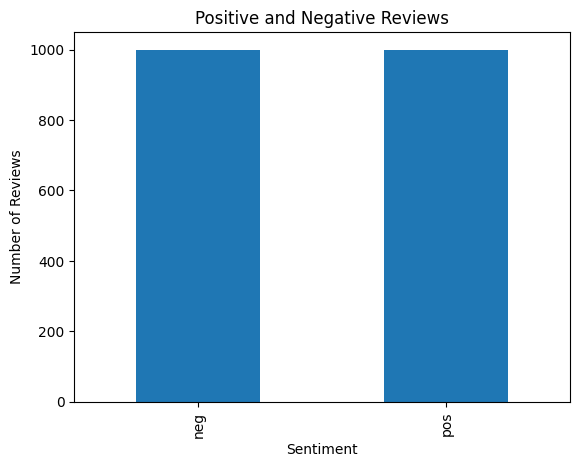


Model Accuracy:
82.0 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.85      0.78      0.81       200
         pos       0.80      0.86      0.83       200

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400


Custom Review Predictions:
This movie was excellent and I really enjoyed it. -> pos
This movie was boring and disappointing. -> neg

Task completed successfully!


In [ ]:
# TASK: SENTIMENT ANALYSIS

import nltk
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import movie_reviews
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

# Download dataset automatically
nltk.download('movie_reviews', quiet=True)

# Load reviews
documents = []
labels = []

for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

df = pd.DataFrame({
    'Review': documents,
    'Sentiment': labels
})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Visualize sentiment distribution
df['Sentiment'].value_counts().plot(kind='bar')
plt.title('Positive and Negative Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    df['Review'],
    df['Sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['Sentiment']
)

# Create and train the model
model = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Evaluate model
print("\nModel Accuracy:")
print(round(accuracy_score(y_test, predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

# Test your own review
reviews = [
    "This movie was excellent and I really enjoyed it.",
    "This movie was boring and disappointing."
]

print("\nCustom Review Predictions:")
for review, sentiment in zip(reviews, model.predict(reviews)):
    print(review, "->", sentiment)

print("\nTask completed successfully!")